[![View notebook](https://img.shields.io/static/v1?label=render%20on&logo=github&color=87ce3e&message=GitHub)](https://github.com/open-atmos/PyPartMC/blob/main/examples/particle_simulation_cpp.ipynb)   
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/open-atmos/PyPartMC/blob/main/examples/particle_simulation_cpp.ipynb)    
[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/open-atmos/PyPartMC.git/main?urlpath=lab/tree/examples/particle_simulation_cpp.ipynb)    
[![ARM JupyterHub](https://img.shields.io/static/v1?label=launch%20in&logo=jupyter&color=lightblue&message=ARM+JupyterHub)](https://jupyterhub.arm.gov/hub/user-redirect/git-pull?repo=https%3A//github.com/open-atmos/PyPartMC&branch=main&urlPath=) (requires [logging in with ARM account](https://www.arm.gov/capabilities/computing-resources) and directing Jupyter to a notebook within the cloned repo)

## C++ version of the urban plume simulation

Following code is based the [urban plume](particle_simulation.ipynb) example notebook, but translated into C++.

In [81]:
import pathlib
import subprocess
import sys
import json
from types import SimpleNamespace
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from open_atmos_jupyter_utils import show_plot

build_dir = pathlib.Path("build_urban_plume")
build_dir.mkdir(exist_ok=True)

In [82]:
%%writefile build_urban_plume/urban_plume.cpp

#include <PyPartMC.hpp>
#include <PyPartMC/si.hpp>
#include <cmath>
#include <fstream>
#include <iostream>
#include <memory>
#include <string>
#include <tuple>
#include <valarray>
#include <vector>

static std::vector<double> to_vec(const std::valarray<double> &va) {
    return std::vector<double>(std::begin(va), std::end(va));
}

int main() {
    using json = nlohmann::ordered_json;

Overwriting build_urban_plume/urban_plume.cpp


In [83]:
%%writefile build_urban_plume/CMakeLists.txt

cmake_minimum_required(VERSION 3.22)
project(UrbanPlumeSimulation LANGUAGES CXX)

set(CMAKE_CXX_STANDARD 17)

find_package(Python 3.8 REQUIRED COMPONENTS Interpreter)
execute_process(
    COMMAND ${Python_EXECUTABLE} -c "import PyPartMC, pathlib; print(pathlib.Path(PyPartMC.cmake_dir()).as_posix())"
    OUTPUT_VARIABLE PYPARTMC_CMAKE_DIR
    OUTPUT_STRIP_TRAILING_WHITESPACE
)
set(PyPartMC_DIR "${PYPARTMC_CMAKE_DIR}")

find_package(PyPartMC REQUIRED)

add_executable(urban_plume urban_plume.cpp)
target_link_libraries(urban_plume PRIVATE PyPartMC::PyPartMC)
pypartmc_setup_runtime(urban_plume)

Overwriting build_urban_plume/CMakeLists.txt


#### Defining gas species (GasData)

In [84]:
%%writefile -a build_urban_plume/urban_plume.cpp
const std::vector<std::string> gas_species = {
    "H2SO4", "HNO3", "HCl", "NH3", "NO", "NO2", "NO3",
    "N2O5", "HONO", "HNO4", "O3", "O1D", "O3P", "OH",
    "HO2", "H2O2", "CO", "SO2", "CH4", "C2H6", "CH3O2",
    "ETHP", "HCHO", "CH3OH", "ANOL", "CH3OOH", "ETHOOH",
    "ALD2", "HCOOH", "RCOOH", "C2O3", "PAN", "ARO1", "ARO2",
    "ALK1", "OLE1", "API1", "API2", "LIM1", "LIM2", "PAR", "AONE",
    "MGLY", "ETH", "OLET", "OLEI", "TOL", "XYL", "CRES", "TO2",
    "CRO", "OPEN", "ONIT", "ROOH", "RO2", "ANO2", "NAP", "XO2",
    "XPAR", "ISOP", "ISOPRD", "ISOPP", "ISOPN", "ISOPO2", "API",
    "LIM", "DMS", "MSA", "DMSO", "DMSO2", "CH3SO2H", "CH3SCH2OO",
    "CH3SO2", "CH3SO3", "CH3SO2OO", "CH3SO2CH2OO", "SULFHOX"
};

auto gas_data = std::make_shared<GasData>();
{
    json gas_json = json::array();
    for (const auto &name : gas_species) {
        gas_json.push_back(json::object({{name, json::array()}}));
    }
    JSONResourceGuard<InputJSONResource> guard(gas_json);
    f_gas_data_from_json(gas_data->ptr.f_arg());
    guard.check_parameters();
}

Appending to build_urban_plume/urban_plume.cpp


#### Defining aerosol species and their properties (AeroData)

In [85]:
%%writefile -a build_urban_plume/urban_plume.cpp

const double kg_m3 = si::kg / std::pow(si::m, 3);
const double g_mol = si::g / si::mol;

json aero_data_json = json::array({
    {{"SO4",  {1800 * kg_m3, 0, 96.0 * g_mol, 0.65,  0, 0}}},
    {{"NO3",  {1800 * kg_m3, 0, 62.0 * g_mol, 0.65,  0, 0}}},
    {{"Cl",   {2200 * kg_m3, 0, 35.5 * g_mol, 1.28,  0, 0}}},
    {{"NH4",  {1800 * kg_m3, 0, 18.0 * g_mol, 0.65,  0, 0}}},
    {{"MSA",  {1800 * kg_m3, 0, 95.0 * g_mol, 0.53,  0, 0}}},
    {{"ARO1", {1400 * kg_m3, 0, 150.0 * g_mol, 0.1,  0, 0}}},
    {{"ARO2", {1400 * kg_m3, 0, 150.0 * g_mol, 0.1,  0, 0}}},
    {{"ALK1", {1400 * kg_m3, 0, 140.0 * g_mol, 0.1,  0, 0}}},
    {{"OLE1", {1400 * kg_m3, 0, 140.0 * g_mol, 0.1,  0, 0}}},
    {{"API1", {1400 * kg_m3, 0, 184.0 * g_mol, 0.1,  0, 0}}},
    {{"API2", {1400 * kg_m3, 0, 184.0 * g_mol, 0.1,  0, 0}}},
    {{"LIM1", {1400 * kg_m3, 0, 200.0 * g_mol, 0.1,  0, 0}}},
    {{"LIM2", {1400 * kg_m3, 0, 200.0 * g_mol, 0.1,  0, 0}}},
    {{"CO3",  {2600 * kg_m3, 0, 60.0 * g_mol, 0.53,  0, 0}}},
    {{"Na",   {2200 * kg_m3, 0, 23.0 * g_mol, 1.28,  0, 0}}},
    {{"Ca",   {2600 * kg_m3, 0, 40.0 * g_mol, 0.53,  0, 0}}},
    {{"OIN",  {2600 * kg_m3, 0, 1.0 * g_mol,  0.1,   0, 0}}},
    {{"OC",   {1400 * kg_m3, 0, 1.0 * g_mol,  0.001, 0}}},
    {{"BC",   {1800 * kg_m3, 0, 1.0 * g_mol,  0,     0, 0}}},
    {{"H2O",  {1000 * kg_m3, 0, 18.0 * g_mol, 0,     0, 0}}}
});
auto aero_data = std::make_shared<AeroData>(aero_data_json);


Appending to build_urban_plume/urban_plume.cpp


#### Initializing gas mixing ratios (GasState)

In [86]:
%%writefile -a build_urban_plume/urban_plume.cpp

GasState gas_state(gas_data);
json mix_rats_json = json::array({
    {{"NO",     {0.1E+00}}},
    {{"NO2",    {1.0E+00}}},
    {{"HNO3",   {1.0E+00}}},
    {{"O3",     {5.0E+01}}},
    {{"H2O2",   {1.1E+00}}},
    {{"CO",     {2.1E+02}}},
    {{"SO2",    {0.8E+00}}},
    {{"NH3",    {0.5E+00}}},
    {{"HCl",    {0.7E+00}}},
    {{"CH4",    {2.2E+03}}},
    {{"C2H6",   {1.0E+00}}},
    {{"HCHO",   {1.2E+00}}},
    {{"CH3OH",  {1.2E-01}}},
    {{"CH3OOH", {0.5E+00}}},
    {{"ALD2",   {1.0E+00}}},
    {{"PAR",    {2.0E+00}}},
    {{"AONE",   {1.0E+00}}},
    {{"ETH",    {0.2E+00}}},
    {{"OLET",   {2.3E-02}}},
    {{"OLEI",   {3.1E-04}}},
    {{"TOL",    {0.1E+00}}},
    {{"XYL",    {0.1E+00}}},
    {{"ONIT",   {0.1E+00}}},
    {{"PAN",    {0.8E+00}}},
    {{"RCOOH",  {0.2E+00}}},
    {{"ROOH",   {2.5E-02}}},
    {{"ISOP",   {0.5E+00}}}
});
GasState::set_mix_rats(gas_state, mix_rats_json);

Appending to build_urban_plume/urban_plume.cpp


### Aerosol size distribution

In [87]:
%%writefile -a build_urban_plume/urban_plume.cpp

const double per_m3 = 1.0 / std::pow(si::m, 3);
json aero_dist_init_json = json::array({
    {
        {"init_small", {
            {"mass_frac", json::array({{{"SO4", {1}}}, {{"OC", {1.375}}}, {{"NH4", {0.375}}}})},
            {"diam_type", "geometric"},
            {"mode_type", "log_normal"},
            {"num_conc", 3.2e9 * per_m3},
            {"geom_mean_diam", 0.02 * si::um},
            {"log10_geom_std_dev", 0.161}
        }},
        {"init_large", {
            {"mass_frac", json::array({{{"SO4", {1}}}, {{"OC", {1.375}}}, {{"NH4", {0.375}}}})},
            {"diam_type", "geometric"},
            {"mode_type", "log_normal"},
            {"num_conc", 2.9e9 * per_m3},
            {"geom_mean_diam", 0.16 * si::um},
            {"log10_geom_std_dev", 0.217}
        }}
    }
});
AeroDist aero_dist_init(aero_data, aero_dist_init_json);

Appending to build_urban_plume/urban_plume.cpp


In [88]:
%%writefile -a build_urban_plume/urban_plume.cpp

json aero_dist_emit_json = {
    {"gasoline", {
        {"mass_frac", json::array({{{"OC", {0.8}}}, {{"BC", {0.2}}}})},
        {"diam_type", "geometric"},
        {"mode_type", "log_normal"},
        {"num_conc", 5e7 * per_m3},
        {"geom_mean_diam", 5e-8 * si::m},
        {"log10_geom_std_dev", 0.24}
    }},
    {"diesel", {
        {"mass_frac", json::array({{{"OC", {0.3}}}, {{"BC", {0.7}}}})},
        {"diam_type", "geometric"},
        {"mode_type", "log_normal"},
        {"num_conc", 1.6e8 * per_m3},
        {"geom_mean_diam", 5e-8 * si::m},
        {"log10_geom_std_dev", 0.24}
    }},
    {"cooking", {
        {"mass_frac", json::array({{{"OC", {1}}}})},
        {"diam_type", "geometric"},
        {"mode_type", "log_normal"},
        {"num_conc", 9e6 * per_m3},
        {"geom_mean_diam", 8.64e-8 * si::m},
        {"log10_geom_std_dev", 0.28}
    }}
};

Appending to build_urban_plume/urban_plume.cpp


#### Emitted gas species

In [89]:
%%writefile -a build_urban_plume/urban_plume.cpp

std::vector<double> gas_emit_times = {
    0, 3600, 7200, 10800, 14400, 18000, 21600, 25200, 28800, 32400, 36000,
    39600, 43200, 46800, 50400, 54000, 57600, 61200, 64800, 68400, 72000,
    75600, 79200, 82800, 90000, 93600, 97200, 100800, 104400, 108000
};
std::vector<double> gas_emit_rates(gas_emit_times.size(), 0.0);
for (size_t i = 0; i < 12; ++i) gas_emit_rates[i] = 0.5;

json emit_gas = json::array({
    {{"time", gas_emit_times}},
    {{"rate", gas_emit_rates}},
    {{"SO2",  {4.234E-09, 5.481E-09, 5.089E-09, 5.199E-09, 5.221E-09, 5.284E-09, 5.244E-09, 5.280E-09, 5.560E-09, 5.343E-09, 4.480E-09, 3.858E-09, 3.823E-09, 3.607E-09, 3.533E-09, 3.438E-09, 2.866E-09, 2.667E-09, 2.636E-09, 2.573E-09, 2.558E-09, 2.573E-09, 2.715E-09, 3.170E-09, 4.2344E-09, 5.481E-09, 5.089E-09, 5.199E-09, 5.221E-09, 5.284E-09}}},
    {{"NO",   {5.749E-08, 6.338E-08, 5.825E-08, 6.237E-08, 6.411E-08, 6.699E-08, 6.468E-08, 6.753E-08, 6.488E-08, 7.575E-08, 6.291E-08, 5.576E-08, 4.524E-08, 3.679E-08, 3.419E-08, 2.924E-08, 1.832E-08, 1.687E-08, 1.515E-08, 1.171E-08, 1.125E-08, 1.202E-08, 1.877E-08, 3.615E-08, 5.749E-08, 6.338E-08, 5.825E-08, 6.237E-08, 6.411E-08, 6.699E-08}}},
    {{"NO2",  {3.024E-09, 3.334E-09, 3.063E-09, 3.281E-09, 3.372E-09, 3.523E-09, 3.402E-09, 3.551E-09, 3.413E-09, 3.985E-09, 3.308E-09, 2.933E-09, 2.380E-09, 1.935E-09, 1.798E-09, 1.537E-09, 9.633E-10, 8.873E-10, 7.968E-10, 6.156E-10, 5.920E-10, 6.320E-10, 9.871E-10, 1.901E-09, 3.024E-09, 3.334E-09, 3.063E-09, 3.281E-09, 3.372E-09, 3.523E-09}}},
    {{"CO",   {7.839E-07, 5.837E-07, 4.154E-07, 4.458E-07, 4.657E-07, 4.912E-07, 4.651E-07, 4.907E-07, 6.938E-07, 8.850E-07, 8.135E-07, 4.573E-07, 3.349E-07, 2.437E-07, 2.148E-07, 1.662E-07, 8.037E-08, 7.841E-08, 6.411E-08, 2.551E-08, 2.056E-08, 3.058E-08, 1.083E-07, 3.938E-07, 7.839E-07, 5.837E-07, 4.154E-07, 4.458E-07, 4.657E-07, 4.912E-07}}},
    {{"NH3",  {8.93E-09, 8.705E-09, 1.639E-08, 1.466E-08, 1.6405E-08, 1.8805E-08, 1.65E-08, 1.8045E-08, 1.347E-08, 6.745E-09, 5.415E-09, 2.553E-09, 2.087E-09, 2.2885E-09, 2.7265E-09, 2.7338E-09, 9.96E-10, 2.707E-09, 9.84E-10, 9.675E-10, 9.905E-10, 1.0345E-09, 1.0825E-09, 2.7465E-09, 8.93E-09, 8.705E-09, 1.639E-08, 1.466E-08, 1.6405E-08, 1.8805E-08}}},
    {{"HCHO", {4.061E-09, 3.225E-09, 2.440E-09, 2.639E-09, 2.754E-09, 2.888E-09, 2.741E-09, 2.885E-09, 4.088E-09, 5.186E-09, 4.702E-09, 2.601E-09, 1.923E-09, 1.412E-09, 1.252E-09, 9.776E-10, 4.687E-10, 4.657E-10, 3.836E-10, 1.717E-10, 1.448E-10, 1.976E-10, 6.193E-10, 2.090E-09, 4.061E-09, 3.225E-09, 2.440E-09, 2.639E-09, 2.754E-09, 2.888E-09}}},
    {{"ALD2", {1.702E-09, 1.283E-09, 9.397E-10, 1.024E-09, 1.076E-09, 1.132E-09, 1.068E-09, 1.130E-09, 1.651E-09, 2.132E-09, 1.985E-09, 1.081E-09, 7.847E-10, 5.676E-10, 5.003E-10, 3.838E-10, 1.784E-10, 1.766E-10, 1.430E-10, 5.173E-11, 4.028E-11, 6.349E-11, 2.428E-10, 8.716E-10, 1.7022E-09, 1.283E-09, 9.397E-10, 1.024E-09, 1.076E-09, 1.132E-09}}},
    {{"ETH",  {1.849E-08, 1.391E-08, 1.010E-08, 1.095E-08, 1.148E-08, 1.209E-08, 1.142E-08, 1.205E-08, 1.806E-08, 2.320E-08, 2.149E-08, 1.146E-08, 8.384E-09, 6.124E-09, 5.414E-09, 4.119E-09, 1.953E-09, 1.927E-09, 1.575E-09, 6.164E-10, 4.973E-10, 7.420E-10, 2.653E-09, 9.477E-09, 1.849E-08, 1.391E-08, 1.010E-08, 1.095E-08, 1.148E-08, 1.209E-08}}},
    {{"OLEI", {5.948E-09, 4.573E-09, 3.374E-09, 3.668E-09, 3.851E-09, 4.050E-09, 3.841E-09, 4.052E-09, 6.094E-09, 7.795E-09, 7.215E-09, 3.738E-09, 2.718E-09, 1.973E-09, 1.729E-09, 1.338E-09, 6.333E-10, 6.394E-10, 5.126E-10, 2.089E-10, 1.708E-10, 2.480E-10, 8.947E-10, 3.057E-09, 5.948E-09, 4.573E-09, 3.374E-09, 3.668E-09, 3.851E-09, 4.050E-09}}},
    {{"OLET", {5.948E-09, 4.573E-09, 3.374E-09, 3.668E-09, 3.851E-09, 4.050E-09, 3.841E-09, 4.052E-09, 6.094E-09, 7.795E-09, 7.215E-09, 3.738E-09, 2.718E-09, 1.973E-09, 1.729E-09, 1.338E-09, 6.333E-10, 6.394E-10, 5.126E-10, 2.089E-10, 1.708E-10, 2.480E-10, 8.947E-10, 3.057E-09, 5.948E-09, 4.573E-09, 3.374E-09, 3.668E-09, 3.851E-09, 4.050E-09}}},
    {{"TOL",  {6.101E-09, 8.706E-09, 7.755E-09, 8.024E-09, 8.202E-09, 8.410E-09, 8.218E-09, 8.407E-09, 1.020E-08, 1.139E-08, 7.338E-09, 4.184E-09, 3.078E-09, 2.283E-09, 2.010E-09, 1.575E-09, 8.966E-10, 6.705E-10, 5.395E-10, 2.462E-10, 2.106E-10, 2.852E-10, 9.300E-10, 3.144E-09, 6.101E-09, 8.706E-09, 7.755E-09, 8.024E-09, 8.202E-09, 8.410E-09}}},
    {{"XYL",  {5.599E-09, 4.774E-09, 3.660E-09, 3.909E-09, 4.060E-09, 4.239E-09, 4.060E-09, 4.257E-09, 6.036E-09, 7.448E-09, 6.452E-09, 3.435E-09, 2.525E-09, 1.859E-09, 1.650E-09, 1.302E-09, 6.852E-10, 6.773E-10, 5.437E-10, 2.697E-10, 2.358E-10, 3.059E-10, 8.552E-10, 2.861E-10, 5.599E-09, 4.774E-09, 3.660E-09, 3.909E-09, 4.060E-09, 4.239E-09}}},
    {{"AONE", {7.825E-10, 2.858E-09, 2.938E-09, 2.947E-09, 2.948E-09, 2.951E-09, 2.947E-09, 2.954E-09, 3.032E-09, 2.766E-09, 1.313E-09, 1.015E-09, 8.363E-10, 7.040E-10, 6.404E-10, 6.264E-10, 5.661E-10, 1.538E-10, 1.500E-10, 1.395E-10, 1.476E-10, 1.503E-10, 2.256E-10, 4.244E-10, 7.825E-10, 2.858E-09, 2.938E-09, 2.947E-09, 2.948E-09, 2.951E-09}}},
    {{"PAR",  {1.709E-07, 1.953E-07, 1.698E-07, 1.761E-07, 1.808E-07, 1.865E-07, 1.822E-07, 1.8599E-07, 2.412E-07, 2.728E-07, 2.174E-07, 1.243E-07, 9.741E-08, 7.744E-08, 6.931E-08, 5.805E-08, 3.900E-08, 3.317E-08, 2.956E-08, 2.306E-08, 2.231E-08, 2.395E-08, 4.284E-08, 9.655E-08, 1.709E-07, 1.953E-07, 1.698E-07, 1.761E-07, 1.808E-07, 1.865E-07}}},
    {{"ISOP", {2.412E-10, 2.814E-10, 3.147E-10, 4.358E-10, 5.907E-10, 6.766E-10, 6.594E-10, 5.879E-10, 5.435E-10, 6.402E-10, 5.097E-10, 9.990E-11, 7.691E-11, 5.939E-11, 5.198E-11, 4.498E-11, 3.358E-11, 2.946E-11, 2.728E-11, 2.183E-11, 1.953E-11, 1.890E-11, 2.948E-11, 1.635E-10, 2.412E-10, 2.814E-10, 3.147E-10, 4.358E-10, 5.907E-10, 6.766E-10}}},
    {{"CH3OH",{2.368E-10, 6.107E-10, 6.890E-10, 6.890E-10, 6.890E-10, 6.889E-10, 6.886E-10, 6.890E-10, 6.890E-10, 5.414E-10, 3.701E-10, 2.554E-10, 1.423E-10, 6.699E-11, 2.912E-11, 2.877E-11, 2.825E-11, 2.056E-12, 2.056E-12, 2.056E-12, 2.435E-12, 2.435E-12, 4.030E-11, 1.168E-10, 2.368E-10, 6.107E-10, 6.890E-10, 6.890E-10, 6.890E-10, 6.889E-10}}},
    {{"ANOL", {5.304E-09, 7.960E-09, 7.649E-09, 7.649E-09, 7.432E-09, 7.428E-09, 7.431E-09, 7.434E-09, 7.434E-09, 6.979E-09, 5.666E-09, 4.361E-09, 4.148E-09, 3.289E-09, 2.858E-09, 2.856E-09, 1.127E-09, 9.615E-10, 9.616E-10, 9.616E-10, 9.654E-10, 9.654E-10, 1.397E-09, 2.264E-09, 5.304E-09, 7.960E-09, 7.649E-09, 7.649E-09, 7.432E-09, 7.428E-09}}}
});

Appending to build_urban_plume/urban_plume.cpp


#### Environmental state (EnvState)

In [90]:
%%writefile -a build_urban_plume/urban_plume.cpp

EnvState env_state(json{
    {"rel_humidity", 0.95},
    {"latitude", 0},
    {"longitude", 0},
    {"altitude", 0 * si::m},
    {"start_time", 21600 * si::s},
    {"start_day", 200}
});

Appending to build_urban_plume/urban_plume.cpp


#### Describing the time evolution of the environment

In [91]:
%%writefile -a build_urban_plume/urban_plume.cpp

std::vector<double> time_timeseries(25);
std::vector<double> pressure_timeseries(25, 1e5);
for (int i = 0; i < 25; ++i) time_timeseries[i] = i * 3600.0;

std::vector<double> temp_timeseries = {
    290.016, 292.5, 294.5, 296.112, 297.649, 299.049, 299.684, 299.509, 299.002,
    298.432, 296.943, 295.153, 293.475, 292.466, 291.972, 291.96, 291.512,
    291.481, 290.5, 290.313, 290.317, 290.362, 290.245, 290.228, 291.466
};
std::vector<double> height_timeseries = {
    171.045, 228.210, 296.987, 366.002, 410.868, 414.272, 417.807, 414.133,
    397.465, 376.864, 364.257, 352.119, 338.660, 322.028, 305.246, 258.497,
    240.478, 187.229, 145.851, 128.072, 110.679, 97.628, 93.034, 93.034, 93.034
};

Appending to build_urban_plume/urban_plume.cpp


#### Background values

In [92]:
%%writefile -a build_urban_plume/urban_plume.cpp

json aero_dist_background_json = {
    {"back_small", {
        {"mass_frac", json::array({{{"SO4", {1}}}, {{"OC", {1.375}}}, {{"NH4", {0.375}}}})},
        {"diam_type", "geometric"},
        {"mode_type", "log_normal"},
        {"num_conc", 3.2e9 * per_m3},
        {"geom_mean_diam", 0.02 * si::um},
        {"log10_geom_std_dev", 0.161}
    }},
    {"back_large", {
        {"mass_frac", json::array({{{"SO4", {1}}}, {{"OC", {1.375}}}, {{"NH4", {0.375}}}})},
        {"diam_type", "geometric"},
        {"mode_type", "log_normal"},
        {"num_conc", 2.9e9 * per_m3},
        {"geom_mean_diam", 0.16 * si::um},
        {"log10_geom_std_dev", 0.217}
    }}
};

Appending to build_urban_plume/urban_plume.cpp


In [93]:
%%writefile -a build_urban_plume/urban_plume.cpp

json back_gas = json::array({
    {{"time", {0 * si::s}}},
    {{"rate", {1.5e-5 / si::s}}},
    {{"NO", {0.1E+00}}}, {{"NO2", {1.0E+00}}}, {{"HNO3", {1.0E+00}}},
    {{"O3", {5.0E+01}}}, {{"H2O2", {1.1E+00}}}, {{"CO", {2.1E+02}}},
    {{"SO2", {0.8E+00}}}, {{"NH3", {0.5E+00}}}, {{"HCl", {0.7E+00}}},
    {{"CH4", {2.2E+03}}}, {{"C2H6", {1.0E+00}}}, {{"HCHO", {1.2E+00}}},
    {{"CH3OH", {1.2E-01}}}, {{"CH3OOH", {0.5E+00}}}, {{"ALD2", {1.0E+00}}},
    {{"PAR", {2.0E+00}}}, {{"AONE", {1.0E+00}}}, {{"ETH", {0.2E+00}}},
    {{"OLET", {2.3E-02}}}, {{"OLEI", {3.1E-04}}}, {{"TOL", {0.1E+00}}},
    {{"XYL", {0.1E+00}}}, {{"ONIT", {0.1E+00}}}, {{"PAN", {0.8E+00}}},
    {{"RCOOH", {0.2E+00}}}, {{"ROOH", {2.5E-02}}}, {{"ISOP", {0.5E+00}}}
});

Appending to build_urban_plume/urban_plume.cpp


#### Finalizing scenario information (Scenario)

In [94]:
%%writefile -a build_urban_plume/urban_plume.cpp

Scenario scenario(*gas_data, *aero_data, json{
    {"temp_profile", json::array({{{"time", time_timeseries}}, {{"temp", temp_timeseries}}})},
    {"pressure_profile", json::array({{{"time", time_timeseries}}, {{"pressure", pressure_timeseries}}})},
    {"height_profile", json::array({{{"time", time_timeseries}}, {{"height", height_timeseries}}})},
    {"gas_emissions", emit_gas},
    {"gas_background", back_gas},
    {"aero_emissions", json::array({
        {{"time", {0 * si::s, 12 * 3600 * si::s}}},
        {{"rate", {1.0 / si::s, 0.0 / si::s}}},
        {{"dist", json::array({json::array({aero_dist_emit_json}), json::array({aero_dist_emit_json})})}}
    })},
    {"aero_background", json::array({
        {{"time", {0 * si::s}}},
        {{"rate", {1.5e-5 / si::s}}},
        {{"dist", json::array({json::array({aero_dist_background_json})})}}
    })},
    {"loss_function", "none"}
});

Appending to build_urban_plume/urban_plume.cpp


In [95]:
%%writefile -a build_urban_plume/urban_plume.cpp

const double T_INITIAL = 0.0;
Scenario::init_env_state(scenario, env_state, T_INITIAL);

Appending to build_urban_plume/urban_plume.cpp


In [96]:
%%writefile -a build_urban_plume/urban_plume.cpp

RunPartOpt run_part_opt(json{
    {"output_prefix", "urban_plume"},
    {"do_coagulation", true},
    {"coag_kernel", "brown"},
    {"t_max", 86400 * si::s},
    {"del_t", 60 * si::s}
});


Appending to build_urban_plume/urban_plume.cpp


#### Sampling the initial aerosol distribution


In [97]:
%%writefile -a build_urban_plume/urban_plume.cpp

const double N_PART = 1000;
AeroState aero_state(aero_data, N_PART, "nummass_source");
AeroState::dist_sample(aero_state, aero_dist_init, 1.0, 0.0, true, true);

Appending to build_urban_plume/urban_plume.cpp


In [98]:
%%writefile -a build_urban_plume/urban_plume.cpp

CampCore camp_core;
Photolysis photolysis;

Appending to build_urban_plume/urban_plume.cpp


#### Running the simulation

In [99]:
%%writefile -a build_urban_plume/urban_plume.cpp

const int N_STEPS = static_cast<int>(RunPartOpt::t_max(run_part_opt) / RunPartOpt::del_t(run_part_opt));
const size_t n_spec = GasState::__len__(gas_state);

std::vector<double> num_conc(N_STEPS + 1, 0.0);
std::vector<double> mass_conc(N_STEPS + 1, 0.0);
std::vector<double> time(N_STEPS + 1, 0.0);
std::vector<std::vector<double>> gas_mix_rat(N_STEPS + 1, std::vector<double>(n_spec, 0.0));
std::vector<double> height(N_STEPS + 1, 0.0);
std::vector<double> temperature(N_STEPS + 1, 0.0);
std::vector<double> rh(N_STEPS + 1, 0.0);

num_conc[0] = AeroState::total_num_conc(aero_state);
mass_conc[0] = AeroState::total_mass_conc(aero_state);
gas_mix_rat[0] = to_vec(GasState::mix_rats(gas_state));
height[0] = EnvState::get_height(env_state);
temperature[0] = EnvState::temp(env_state);
rh[0] = EnvState::rh(env_state);

BinGrid diam_grid;
{
    int n_bin = 30, type = 1;
    double min_d = 1e-9, max_d = 1e-6;
    f_bin_grid_init(diam_grid.ptr.f_arg(), &n_bin, &type, &min_d, &max_d);
}

std::vector<std::vector<double>> dists;
dists.push_back(to_vec(histogram_1d(
    diam_grid,
    AeroState::dry_diameters(aero_state),
    AeroState::num_concs(aero_state)
)));

double last_output_time = 0.0;
double last_progress_time = 0.0;
int i_output = 1;
const double del_t = RunPartOpt::del_t(run_part_opt);

for (int i_time = 1; i_time <= N_STEPS; ++i_time) {
    std::tie(last_output_time, last_progress_time, i_output) = run_part_timestep(
        scenario,
        env_state,
        *aero_data,
        aero_state,
        *gas_data,
        gas_state,
        run_part_opt,
        camp_core,
        photolysis,
        i_time,
        T_INITIAL,
        last_output_time,
        last_progress_time,
        i_output
    );

    num_conc[i_time] = AeroState::total_num_conc(aero_state);
    mass_conc[i_time] = AeroState::total_mass_conc(aero_state);
    time[i_time] = EnvState::get_elapsed_time(env_state);
    gas_mix_rat[i_time] = to_vec(GasState::mix_rats(gas_state));
    height[i_time] = EnvState::get_height(env_state);
    temperature[i_time] = EnvState::temp(env_state);
    rh[i_time] = EnvState::rh(env_state);

    if (std::fmod(i_time * del_t, 3600.0) == 0.0) {
        dists.push_back(to_vec(histogram_1d(
            diam_grid,
            AeroState::dry_diameters(aero_state),
            AeroState::num_concs(aero_state)
        )));
    }
}

BinGrid mass_frac_grid;
{
    int n_bin = 100, type = 2;
    double min_mf = 0.0, max_mf = 1.0;
    f_bin_grid_init(mass_frac_grid.ptr.f_arg(), &n_bin, &type, &min_mf, &max_mf);
}

auto num_concs = AeroState::num_concs(aero_state);
auto dry_diameters = AeroState::dry_diameters(aero_state);
auto bc_masses = AeroState::masses(aero_state, std::vector<std::string>{"BC"}, tl::nullopt);
auto dry_masses = AeroState::masses(aero_state, tl::nullopt, std::vector<std::string>{"H2O"});
std::valarray<double> species_mass_frac = bc_masses / dry_masses;

auto vals = histogram_2d(
    diam_grid, dry_diameters, mass_frac_grid, species_mass_frac, num_concs
);

json spec_indices = json::object();
for (const auto &g : {"NO", "NO2", "O3", "HNO3", "SO2", "NH3"}) {
    spec_indices[g] = GasData::spec_by_name(*gas_data, g);
}

json out;
out["time"] = time;
out["temperature"] = temperature;
out["rh"] = rh;
out["height"] = height;
out["num_conc"] = num_conc;
out["mass_conc"] = mass_conc;
out["gas_mix_rat"] = gas_mix_rat;
out["spec_indices"] = spec_indices;
out["diam_grid_centers"] = to_vec(BinGrid::centers(diam_grid));
out["diam_grid_edges"] = to_vec(BinGrid::edges(diam_grid));
out["mass_frac_grid_edges"] = to_vec(BinGrid::edges(mass_frac_grid));
out["dists"] = dists;
out["vals"] = vals;

std::ofstream ofs("output.json");
ofs << out.dump();
} // closing main function

Appending to build_urban_plume/urban_plume.cpp


In [100]:
from types import SimpleNamespace

def run_cmd(cmd, cwd):
    res = subprocess.run(cmd, cwd=cwd, capture_output=True, text=True)
    if res.stdout:
        print(res.stdout)
    if res.stderr:
        print(res.stderr, file=sys.stderr)
    res.check_returncode()

run_cmd(["cmake", "-G", "Ninja", "."], cwd=build_dir)
run_cmd(["cmake", "--build", "."], cwd=build_dir)

exe_name = "urban_plume.exe" if sys.platform.startswith("win") else "./urban_plume"
run_cmd([str(build_dir / exe_name)], cwd=build_dir)

data = json.loads((build_dir / "output.json").read_text(encoding="utf-8"))

time = np.array(data["time"])
temperature = np.array(data["temperature"])
rh = np.array(data["rh"])
height = np.array(data["height"])
num_conc = np.array(data["num_conc"])
mass_conc = np.array(data["mass_conc"])
gas_mix_rat = np.array(data["gas_mix_rat"])
dists = [np.array(d) for d in data["dists"]]
vals = np.array(data["vals"])

diam_grid = SimpleNamespace(
    centers=np.array(data["diam_grid_centers"]),
    edges=np.array(data["diam_grid_edges"]),
)
mass_frac_grid = SimpleNamespace(
    edges=np.array(data["mass_frac_grid_edges"]),
)
gas_data = SimpleNamespace(
    spec_by_name=lambda spec: data["spec_indices"][spec]
)

-- Found Python: D:/atmos/PyPartMCcpp/venv/Scripts/python.exe (found suitable version "3.13.9", minimum required is "3.8") found components: Interpreter
-- Found Python: D:/atmos/PyPartMCcpp/venv/Scripts/python.exe (found suitable version "3.13.9", minimum required is "3.8") found components: Interpreter Development Development.Module Development.Embed
-- Found PyPartMC: D:\atmos\PyPartMCcpp\venv\Lib\site-packages\PyPartMC
-- Configuring done (0.7s)
-- Generating done (0.1s)
-- Build files have been written to: D:/atmos/PyPartMCcpp/readme_cpp/examples/build_urban_plume

[1/2] Building CXX object CMakeFiles/urban_plume.dir/urban_plume.cpp.obj
[2/2] Linking CXX executable urban_plume.exe



### Analysis

In [101]:
plt.rcParams.update({'font.size': 9})
plt.rcParams.update({'figure.figsize': (3.08,2.5)})
plt.rcParams.update({"axes.grid" : True})

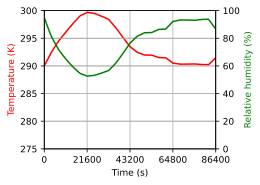

In [102]:
plt.plot(time,temperature,'r')
plt.ylabel('Temperature (K)', color='r')
plt.ylim([275,300])
plt.xticks(np.linspace(0, time[-1], 5))
plt.xlim([0,time[-1]])
plt.xlabel('Time (s)')
plt.twinx()
plt.plot(time,rh*100,'g')
plt.ylabel('Relative humidity (%)', color='g')
plt.ylim([0,100])
show_plot("build_urban_plume/ambient_thermodynamics")

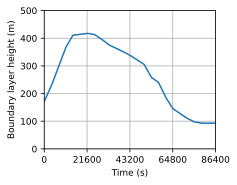

In [103]:
plt.plot(time,height)
plt.xticks(np.linspace(0, time[-1], 5))
plt.xlim([0,time[-1]])
plt.xlabel('Time (s)')
plt.ylim([0,500])
plt.ylabel('Boundary layer height (m)')
show_plot("build_urban_plume/Boundary_layer_height")

In [104]:
def set_tickmarks(axes, n_ticks):
    ylims = axes.get_ylim()
    if np.log10(ylims[0]) > 1:
        val = -int(np.ceil(np.abs(np.log10(ylims[0])))) + 1
    else:
        val = int(np.ceil(np.abs(np.log10(ylims[0])))) + 1     
    ymin = round(ylims[0] - .1 * ylims[0], val)
    ymax = round(ylims[1] + .1 * ylims[1], val)
    plt.ylim([ymin, ymax])
    plt.yticks(np.linspace(ymin, ymax, n_ticks))

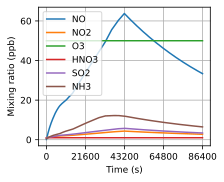

In [105]:
gases = ["NO", "NO2", "O3", "HNO3", "SO2", "NH3"]
for i_spec, spec in enumerate(gases):
    i_spec = gas_data.spec_by_name(spec)
    l, = plt.plot(time, gas_mix_rat[:, i_spec], label=spec)
plt.xlabel("Time (s)")
plt.ylabel("Mixing ratio (ppb)")
plt.xticks(np.linspace(0, time[-1], 5))
plt.legend()
show_plot("build_urban_plume/Gas_mixing_ratios")

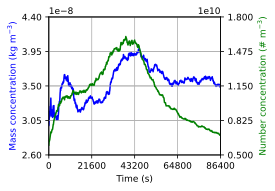

In [106]:
plt.plot(time, mass_conc, "b", label="mass conc")
plt.ylabel("Mass concentration (kg m$^{-3}$)", color='b')
plt.xlabel("Time (s)")
set_tickmarks(plt.gca(), 5)
plt.twinx()
plt.plot(time, num_conc, "g", label="num conc")
plt.xticks(np.linspace(0, time[-1], 5))
plt.xlim([time[0],time[-1]])
set_tickmarks(plt.gca(), 5)
plt.ylabel(r"Number concentration ($\#$ m$^{-3}$)", color='g')
show_plot("build_urban_plume/Particle_concentrations")

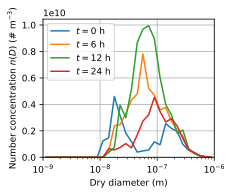

In [107]:
plt.plot(diam_grid.centers, dists[0],label='$t = 0$ h')
plt.plot(diam_grid.centers, dists[6],label='$t = 6$ h')
plt.plot(diam_grid.centers, dists[12],label='$t = 12$ h')
plt.plot(diam_grid.centers, dists[24],label='$t = 24$ h')
plt.xscale("log")
plt.xlabel("Dry diameter (m)")
plt.ylabel(r"Number concentration $n(D)$ ($\#$ m$^{-3}$)")
plt.ylim(bottom=0)
plt.legend()
plt.xlim([diam_grid.edges[0],diam_grid.edges[-1]])
show_plot("build_urban_plume/size_spectrum")

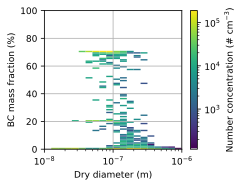

In [108]:
plt.pcolormesh(
    diam_grid.edges,
    np.array(mass_frac_grid.edges)*100,
    np.array(vals).T / 1e6,
    norm=matplotlib.colors.LogNorm(),
)
plt.xscale("log")
plt.xlim([1e-8, 1e-6])
plt.colorbar(label=r"Number concentration ($\#$ cm$^{-3}$)")
plt.xlabel("Dry diameter (m)")
plt.ylabel("BC mass fraction (%)")
show_plot("build_urban_plume/BC_mass_fraction_vs_size")